In [ ]:
def set_seed(seed: int = 42) -> None:
    """
    Set random seeds for reproducibility. Defaults to 42.

    Args:
        seed (int): Seed value.

    Returns:
        None: Sets the seed to a given value or 42.
    """
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed(42)

In [ ]:
if torch.cuda.is_available():
    print(f"Using GPU: {torch.cuda.get_device_name(0)}")
    device = torch.device("cuda")
else:
    print("Using CPU")
    device = torch.device("cpu")

Using GPU: Tesla T4


In [ ]:
class AGNewsDataset(Dataset):
    """
    A custom dataset class for the AG News dataset.
    """

    def __init__(self, encodings: dict, labels: list) -> None:
        """
        Constructor for the AGNewsDataset class.

        Args:
            encodings (dict): A dictionary containing the tokenized input data.
            labels (list): A list of labels corresponding to the input data.

        Returns:
            None: Initializes the dataset with the provided encodings and labels.
        """
        self.encodings = encodings
        self.labels = list(labels)

    def __len__(self) -> int:
        """
        Returns the length of the dataset.

        Args:
            None

        Returns:
            int: The number of samples in the dataset.
        """
        return len(self.labels)

    def __getitem__(self, idx: int) -> dict:
        """
        Returns a single sample from the dataset at the specified index.

        Args:
            idx (int): The index of the sample to retrieve.

        Returns:
            dict: A dictionary containing the input IDs, attention mask, and label for the specified sample.
        """
        return {
            "input_ids": self.encodings["input_ids"][idx],
            "attention_mask": self.encodings["attention_mask"][idx],
            "label": self.labels[idx],
        }

In [ ]:
splits = {'train': 'train.jsonl', 'test': 'test.jsonl'}
df_train = pd.read_json("hf://datasets/sh0416/ag_news/" + splits["train"], lines=True)
test_dataset = pd.read_json("hf://datasets/sh0416/ag_news/" + splits["test"], lines=True)

train_dataset, val_dataset = train_test_split(
    df_train,
    test_size=0.1,
    random_state=42,
    stratify=df_train["label"]
)

X_train = train_dataset["title"] + " " + train_dataset["description"]
y_train = train_dataset["label"]

X_val = val_dataset["title"] + " " + val_dataset["description"]
y_val = val_dataset["label"]

X_test = test_dataset["title"] + " " + test_dataset["description"]
y_test = test_dataset["label"]

In [ ]:
def to_zero_indexed(series: pd.Series) -> list:
    """
    Convert a pandas Series of labels to zero-indexed format.

    Args:
        series (pd.Series): A pandas Series containing the labels.

    Returns:
        list: A list of zero-indexed labels.
    """
    return (series - 1).tolist()

In [ ]:
tokenizer = AutoTokenizer.from_pretrained(TRANSFORMER_CONFIG["model_name"])

train_encodings = tokenizer(
    X_train.tolist(),
    truncation=True,
    max_length=TRANSFORMER_CONFIG["max_len"],
)

val_encodings = tokenizer(
    X_val.tolist(),
    truncation=True,
    max_length=TRANSFORMER_CONFIG["max_len"],
)

test_encodings = tokenizer(
    X_test.tolist(),
    truncation=True,
    max_length=TRANSFORMER_CONFIG["max_len"],
)

train_labels_0 = to_zero_indexed(y_train)
val_labels_0   = to_zero_indexed(y_val)
test_labels_0  = to_zero_indexed(y_test)

tokenized_train = AGNewsDataset(train_encodings, train_labels_0)
tokenized_val   = AGNewsDataset(val_encodings, val_labels_0)
tokenized_test  = AGNewsDataset(test_encodings, test_labels_0)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

In [ ]:
def compute_metrics(eval_pred: tuple) -> dict:
    """
    Compute accuracy and macro F1 score for model evaluation.

    Args:
        eval_pred (tuple): A tuple containing the model's predictions and true labels.

    Returns:
        dict: A dictionary containing accuracy and macro F1 score.
    """
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)

    acc = accuracy_score(labels, preds)
    f1 = f1_score(labels, preds, average="macro")

    return {"accuracy": acc, "macro_f1": f1}

In [ ]:
set_seed(42)
model = AutoModelForSequenceClassification.from_pretrained(
    TRANSFORMER_CONFIG["model_name"],
    num_labels=TRANSFORMER_CONFIG["num_classes"],
)

training_args = TrainingArguments(
    output_dir="./results",
    eval_strategy="epoch",
    logging_strategy="epoch",
    save_strategy="epoch",
    learning_rate=TRANSFORMER_CONFIG["lr"],
    per_device_train_batch_size=TRANSFORMER_CONFIG["batch_size"],
    per_device_eval_batch_size=TRANSFORMER_CONFIG["batch_size"],
    num_train_epochs=TRANSFORMER_CONFIG["epochs"],
    weight_decay=TRANSFORMER_CONFIG["weight_decay"],
    load_best_model_at_end=True,
    metric_for_best_model="loss",
    greater_is_better=False,
    save_total_limit=2,
    seed=42,
    report_to="none",
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,
    data_collator=DataCollatorWithPadding(tokenizer),
    processing_class=tokenizer,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=TRANSFORMER_CONFIG["patience"])]
)

trainer.train()
trainer.save_model("transformer_model")
tokenizer.save_pretrained("transformer_model")


model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.229505,0.170449,0.942500,0.942489
2,0.136877,0.183564,0.943167,0.943107
3,0.095675,0.194449,0.948667,0.948621
4,0.065200,0.216638,0.946417,0.946368


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('transformer_model/tokenizer_config.json', 'transformer_model/tokenizer.json')

In [ ]:
def learning_curves(log_history: list) -> None:
    """
    Plot learning curves for training and evaluation metrics.

    Args:
        log_history (list): A list of dictionaries containing training and evaluation metrics.

    Returns:
        None: Displays the learning curve for validation loss.
    """
    evals = [x for x in log_history if "eval_loss" in x]

    eval_epochs = [x["epoch"] for x in evals]
    eval_loss = [x["eval_loss"] for x in evals]

    best_idx = int(np.argmin(eval_loss))
    best_epoch = eval_epochs[best_idx]
    best_loss = eval_loss[best_idx]

    fig, ax = plt.subplots(figsize=(9, 5))

    ax.plot(
        eval_epochs,
        eval_loss,
        marker="s",
        linewidth=2,
        markersize=6,
        label="Validation loss",
    )

    ax.axvline(
        best_epoch,
        color="gray",
        linestyle="--",
        linewidth=1.5,
        alpha=0.8,
        label=f"Best epoch ({best_epoch:g})",
    )

    ax.scatter(
        best_epoch,
        best_loss,
        color="red",
        s=90,
        zorder=5,
        label=f"Lowest validation loss ({best_loss:.4f})",
    )

    ax.set_title("LSTM Learning Curve", fontsize=15, fontweight="bold", pad=15)
    ax.set_xlabel("Epoch", fontsize=12)
    ax.set_ylabel("Cross-Entropy Loss", fontsize=12)

    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(True, linestyle="--", alpha=0.3)
    ax.legend(frameon=False, fontsize=10)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    fig.tight_layout()
    plt.show()

In [ ]:
def plot_confusion_matrix(y_true, y_pred, title: str) -> None:
    """
    Plot the confusion matrix for the given true and predicted labels.

    Args:
        y_true (array-like): True labels.
        y_pred (array-like): Predicted labels.
        title (str): Title for the confusion matrix plot.

    Returns:
        None: Displays the confusion matrix plot.
    """
    cm = confusion_matrix(y_true, y_pred)
    _, ax = plt.subplots(figsize=(5, 4))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=LABELS.values())
    disp.plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(title, fontsize=11, fontweight="bold")
    plt.tight_layout()
    plt.show()

In [ ]:
eval_results = trainer.evaluate()
print(f"Evaluation Results: {eval_results}")

test_results = trainer.predict(tokenized_test)
test_preds = np.argmax(test_results.predictions, axis=-1)
test_labels_list = test_results.label_ids

test_acc = accuracy_score(test_labels_list, test_preds)
test_f1 = f1_score(test_labels_list, test_preds, average="macro")
print(f"Test Accuracy: {test_acc:.4f}")
print(f"Test Macro-F1: {test_f1:.4f}")

Training Loss,Validation Loss,Epoch,Accuracy,Macro F1
0.065200,0.170449,4,0.942500,0.942489


Evaluation Results: {'eval_loss': 0.17044870555400848, 'eval_accuracy': 0.9425, 'eval_macro_f1': 0.9424893681768621}


Test Accuracy: 0.9393
Test Macro-F1: 0.9394


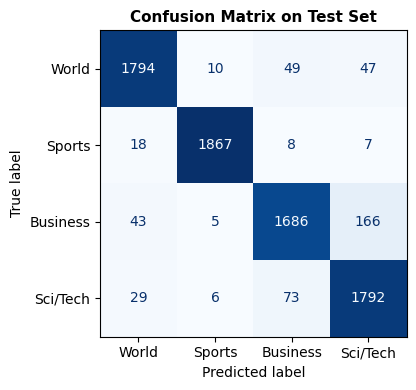

In [ ]:
plot_confusion_matrix(test_labels_list, test_preds, title="Confusion Matrix on Test Set")

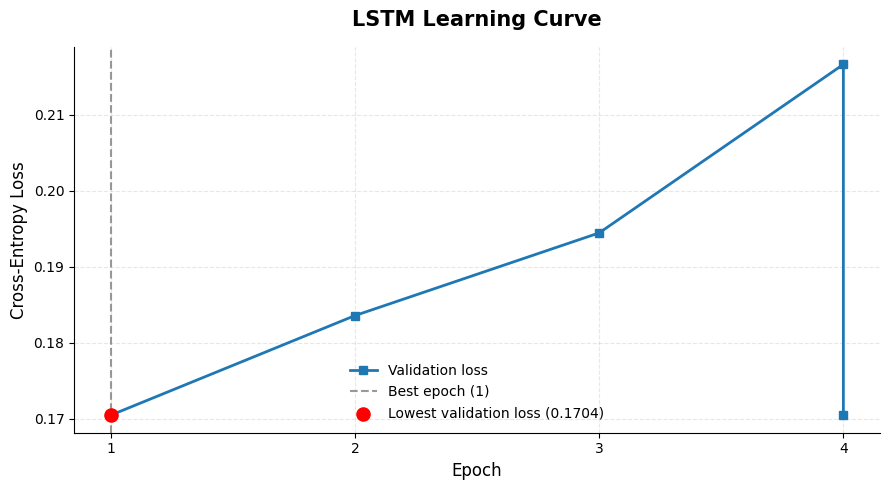

In [ ]:
log_history = trainer.state.log_history
learning_curves(log_history)

In [ ]:
def collect_errors(texts: pd.Series, true_labels: np.ndarray, pred_labels: np.ndarray, label_map: dict, n: int = 20) -> pd.DataFrame:
    """
    Returns a DataFrame of n randomly selected misclassified examples.

    Args:
        texts (pd.Series): A Series of text examples.
        true_labels (np.ndarray): An array of true labels.
        pred_labels (np.ndarray): An array of predicted labels.
        label_map (dict): A dictionary mapping label indices to their string representations.
        n (int): The number of misclassified examples to return.

    Returns:
        pd.DataFrame: A DataFrame containing the misclassified examples.
    """
    texts_list = texts.tolist() if hasattr(texts, "tolist") else list(texts)
    rows = []
    for i, (true, pred) in enumerate(zip(true_labels, pred_labels)):
        if true != pred:
            rows.append({
                "text":       texts_list[i],
                "true_label": label_map[true + 1],
                "pred_label": label_map[pred + 1],
            })
    return pd.DataFrame(rows).sample(n=min(n, len(rows)), random_state=42).reset_index(drop=True)

In [ ]:
error_df = collect_errors(X_test, test_labels_list, test_preds, LABELS, n=20)

print("\n 20 randomly selected misclassified examples (DistilBERT):\n")
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 120)

display(error_df)


 20 randomly selected misclassified examples (DistilBERT):



,text,true_label,pred_label
0,Ban for former Ahold executives Dutch retailer Ahold's former chairman and its ex-finance officer are barred from e...,World,Business
1,Oil Eases as Iraq Resumes Exports &lt;p&gt;\&lt;/p&gt;&lt;p&gt; By Andrew Mitchell&lt;/p&gt;&lt;p&gt; LONDON (Reuter...,Business,World
2,MOM 2005 Released to Manufacturing Microsoft on Wednesday announced the release to manufacturing of Microsoft Operat...,Business,Sci/Tech
3,"Ljubicic Downs Hanescu at Open De Moselle Top-seeded Ivan Ljubicic of Croatia beat Victor Hanescu of Romania 6-4, 6-...",World,Sports
4,Clouds darken PeopleSoft conference SAN FRANCISCO -- PeopleSoft Inc. is trying to create a party-like atmosphere at ...,Business,Sci/Tech
5,Clubbing Wet Seal A same-stores sales drop that's less crummy than expected can't fix this sick pup.,Business,Sci/Tech
6,EasyMobile launch set for March Denmark #39;s leading telecoms operator TDC says it will launch a low-budget mobile ...,Business,Sci/Tech
7,"Legendary all-rounder Miller dies Keith Miller, arguably Australia's greatest all-rounder in Test cricket, has died...",World,Sports
8,Boys 'cured' with gene therapy Gene therapy can cure children born with a condition that knocks out their natural d...,World,Sci/Tech
9,EU foreign ministers hope to break deadlock over ASEM summit The European Union said Friday it quot;hoped to reach ...,Business,World


In [ ]:
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from matplotlib.ticker import MaxNLocator
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    EarlyStoppingCallback,
    Trainer,
    TrainingArguments,
)

LABELS = {1: "World", 2: "Sports", 3: "Business", 4: "Sci/Tech"}

TRANSFORMER_CONFIG = {
    "model_name": "distilbert-base-uncased",
    "max_len": 128,
    "batch_size": 32,
    "lr": 2e-5,
    "epochs": 5,
    "patience": 3,
    "num_classes": 4,
    "weight_decay": 0.01,
}